# Nvidia: Narrative vs Fundamentals
### What moves the stock price around earnings announcements?

This project studies Nvidia's stock reaction to its quarterly earnings announcements.
It combines a market-model event study with a test of whether the reaction is explained by the
earnings surprise (fundamentals) or by something else, such as guidance and the AI narrative.

**Structure**
1. Data
2. Market model (full sample)
3. Earnings announcements
4. Abnormal returns and CARs
5. Is the reaction significant?
6. Narrative vs fundamentals: does the EPS surprise explain the reaction?
7. Charts
8. Findings, limitations and next steps

## 1. Data
Daily adjusted prices for Nvidia (NVDA) and the S&P 500 (^GSPC). The end date is fixed so that results are reproducible.

In [8]:
import pandas as pd
import numpy as np
import yfinance as yf
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

# Parametri dello studio: se li cambi qui, basta "Runtime -> Esegui tutte"
TITOLO = "NVDA"
MERCATO = "^GSPC"
INIZIO = "2020-01-01"
FINE = "2026-11-12"            # data fissa: chi riesegue ottiene gli stessi numeri
FINESTRA_STIMA = (-250, -30)   # giorni di borsa rispetto al giorno 0
FINESTRA_EVENTO = (-1, 1)      # finestra del CAR
FINESTRA_GRAFICO = (-5, 5)     # finestra per il grafico del CAR medio

prezzi = yf.download([TITOLO, MERCATO], start=INIZIO, end=FINE,
                     auto_adjust=True, progress=False)["Close"]

rend = prezzi.pct_change().dropna()
rend = rend.rename(columns={MERCATO: "Mercato"})

print(rend.shape)
print(rend.corr().round(3))

(1724, 2)
Ticker    NVDA  Mercato
Ticker                 
NVDA     1.000    0.698
Mercato  0.698    1.000


## 2. Market model (full sample)
OLS regression of Nvidia's daily returns on S&P 500 returns: R_NVDA = α + β·R_M + ε.
This is only to understand the relationship; in the event study α and β are re-estimated before each announcement.

In [9]:
y = rend[TITOLO]
X = sm.add_constant(rend["Mercato"])
modello = sm.OLS(y, X).fit()

print(modello.summary().tables[1])
print(f"R²: {modello.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0015      0.001      2.595      0.010       0.000       0.003
Mercato        1.7856      0.044     40.394      0.000       1.699       1.872
R²: 0.487


## 3. Earnings announcements
Announcement dates, consensus EPS estimate and reported EPS (source: Yahoo Finance).
Nvidia reports **after the US market close**, so day 0 is the **first trading day after** the release.

In [10]:
trimestrali = yf.Ticker(TITOLO).get_earnings_dates(limit=40)

# Solo trimestrali gia' pubblicate, date senza ora e fuso, in ordine cronologico
trim = trimestrali.dropna(subset=["Reported EPS"]).copy()
trim.index = trim.index.tz_localize(None).normalize()
trim = trim.sort_index()
trim = trim[trim.index < rend.index[-1]]

# Giorno 0 = primo giorno di borsa DOPO l'annuncio
date_borsa = rend.index
giorno0 = []
for d in trim.index:
    successivi = date_borsa[date_borsa > d]
    giorno0.append(successivi[0])
trim["Giorno0"] = giorno0

# Tieni solo eventi con abbastanza storia prima (stima) e dopo (grafico)
primo_ok = date_borsa[-FINESTRA_STIMA[0] + 10]
ultimo_ok = date_borsa[-1 - FINESTRA_GRAFICO[1]]
trim = trim[(trim["Giorno0"] >= primo_ok) & (trim["Giorno0"] <= ultimo_ok)]

print(trim)
print(trim.shape)

               EPS Estimate  Reported EPS  Surprise(%)    Giorno0
Earnings Date                                                    
2021-02-24             0.07          0.08        10.37 2021-02-25
2021-05-26             0.08          0.09        11.44 2021-05-27
2021-08-18             0.10          0.10         2.26 2021-08-19
2021-11-17             0.11          0.12         5.81 2021-11-18
2022-02-16             0.12          0.13         7.97 2022-02-17
2022-05-25             0.13          0.14         4.86 2022-05-26
2022-08-24             0.05          0.05        -1.49 2022-08-25
2022-11-16             0.07          0.06       -17.32 2022-11-17
2023-02-22             0.08          0.09         9.45 2023-02-23
2023-05-24             0.09          0.11        18.80 2023-05-25
2023-08-23             0.21          0.27        29.35 2023-08-24
2023-11-21             0.34          0.40        18.73 2023-11-22
2024-02-21             0.46          0.52        11.40 2024-02-22
2024-05-22

## 4. Abnormal returns and CARs
For each announcement the market model is estimated over trading days [-250, -30] relative to day 0.
The gap before the event keeps any pre-announcement drift out of the estimate.

- AR = R_NVDA − (α + β·R_M)
- CAR = sum of ARs over [-1, +1]
- SCAR = CAR / (σ·√L), the event's own t-statistic (σ = residual std. dev. in the estimation window, L = window length)

In [11]:
def market_model(pos):
    """Stima alpha e beta nella finestra di stima, a partire dalla posizione del giorno 0."""
    dati_stima = rend.iloc[pos + FINESTRA_STIMA[0] : pos + FINESTRA_STIMA[1] + 1]
    X = sm.add_constant(dati_stima["Mercato"])
    return sm.OLS(dati_stima[TITOLO], X).fit()


def ar_evento(giorno0, finestra):
    """Rendimenti anomali di un evento, indicizzati per giorno relativo (-1, 0, +1...)."""
    pos = rend.index.get_loc(giorno0)
    mod = market_model(pos)
    ev = rend.iloc[pos + finestra[0] : pos + finestra[1] + 1]
    ar = ev[TITOLO] - (mod.params["const"] + mod.params["Mercato"] * ev["Mercato"])
    ar.index = range(finestra[0], finestra[1] + 1)
    return ar, mod


righe = []
ar_grafico = {}

for annuncio, riga in trim.iterrows():          # iterrows: una riga della tabella per giro
    d0 = riga["Giorno0"]
    ar, mod = ar_evento(d0, FINESTRA_EVENTO)
    sigma = mod.resid.std()
    car = ar.sum()

    righe.append({
        "Giorno0": d0,
        "CAR": car,
        "SCAR": car / (sigma * np.sqrt(len(ar))),
        "Beta": mod.params["Mercato"],
        "Sigma": sigma,
        "Surprise": riga["Surprise(%)"],
    })
    ar_grafico[d0] = ar_evento(d0, FINESTRA_GRAFICO)[0]

tab = pd.DataFrame(righe).set_index("Giorno0")
ar_grafico = pd.DataFrame(ar_grafico)           # righe = giorni relativi, colonne = eventi

print(tab.round(3))

              CAR   SCAR   Beta  Sigma  Surprise
Giorno0                                         
2021-02-25 -0.010 -0.256  1.298  0.023     10.37
2021-05-27  0.030  0.792  1.501  0.022     11.44
2021-08-19  0.070  1.882  1.732  0.022      2.26
2021-11-18  0.091  2.580  1.668  0.020      5.81
2022-02-17 -0.055 -1.398  2.169  0.023      7.97
2022-05-26  0.020  0.517  2.445  0.023      4.86
2022-08-25 -0.013 -0.321  2.345  0.023     -1.49
2022-11-17 -0.059 -1.531  2.227  0.022    -17.32
2023-02-23  0.144  3.857  2.147  0.022      9.45
2023-05-25  0.228  5.805  2.049  0.023     18.80
2023-08-24 -0.013 -0.279  2.089  0.027     29.35
2023-11-22 -0.072 -1.567  2.195  0.027     18.73
2024-02-22  0.085  1.939  1.982  0.025     11.40
2024-05-23  0.113  2.528  2.363  0.026      9.74
2024-08-29 -0.086 -2.077  2.309  0.024      5.66
2024-11-21 -0.066 -1.484  2.864  0.026      8.52
2025-02-27 -0.012 -0.277  2.607  0.025      5.25
2025-05-29  0.001  0.020  2.220  0.026      8.02
2025-08-28 -0.043 -1

## 5. Is the reaction significant?
- **Direction:** is the average CAR different from zero? (cross-sectional t-test, plus the Wilcoxon signed-rank test, which does not assume normality; residuals have fat tails)
- **Size:** how many single announcements move the stock significantly (|SCAR| > 1.96)?
- **Robustness:** results without the single largest event

In [12]:
car = tab["CAR"]

print(f"Eventi:              {len(car)}")
print(f"CAR medio:           {car.mean():.2%}")
print(f"CAR mediano:         {car.median():.2%}")
print(f"CAR positivi:        {(car > 0).mean():.0%}")
print(f"|CAR| medio:         {car.abs().mean():.2%}")

t, p = stats.ttest_1samp(car, 0)
_, p_w = stats.wilcoxon(car)
print(f"\nTest t (media = 0):       t = {t:.2f}, p = {p:.3f}")
print(f"Wilcoxon (mediana = 0):   p = {p_w:.3f}")

significativi = (tab["SCAR"].abs() > 1.96).sum()
print(f"\nEventi singolarmente significativi (|SCAR| > 1.96): {significativi} su {len(tab)}")

# Robustezza: senza l'evento con il CAR piu' alto
senza_max = car.drop(car.idxmax())
t2, p2 = stats.ttest_1samp(senza_max, 0)
print(f"\nSenza l'evento piu' forte ({car.idxmax().date()}): "
      f"CAR medio {senza_max.mean():.2%}, t = {t2:.2f}, p = {p2:.3f}")

Eventi:              23
CAR medio:           0.99%
CAR mediano:         -1.04%
CAR positivi:        43%
|CAR| medio:         5.99%

Test t (media = 0):       t = 0.60, p = 0.558
Wilcoxon (mediana = 0):   p = 0.870

Eventi singolarmente significativi (|SCAR| > 1.96): 7 su 23

Senza l'evento piu' forte (2023-05-25): CAR medio 0.00%, t = 0.00, p = 0.999


## 6. Narrative vs fundamentals: does the EPS surprise explain the reaction?
Cross-sectional regression of the CAR on the EPS surprise (% vs consensus), with heteroskedasticity-robust standard errors.
If the reaction were driven by the reported numbers, the surprise coefficient should be positive and the R² meaningful.
The sample is also split around May 2023, the start of the AI-driven re-rating.

In [13]:
X = sm.add_constant(tab["Surprise"])
reg_sorpresa = sm.OLS(tab["CAR"], X).fit(cov_type="HC1")    # come ", robust" in Stata

print(reg_sorpresa.summary().tables[1])
print(f"R²: {reg_sorpresa.rsquared:.3f}")

# Prima e dopo il boom dell'AI
taglio = pd.Timestamp("2023-05-25")
prima = tab[tab.index < taglio]
dopo = tab[tab.index >= taglio]
print(f"\nCorrelazione CAR-sorpresa prima di mag-2023: {prima['CAR'].corr(prima['Surprise']):.2f} ({len(prima)} eventi)")
print(f"Correlazione CAR-sorpresa da mag-2023 in poi:{dopo['CAR'].corr(dopo['Surprise']):.2f} ({len(dopo)} eventi)")
print(f"Beat (sorpresa > 0): {(tab['Surprise'] > 0).sum()} su {len(tab)}, "
      f"ma CAR negativo in {(tab['CAR'] < 0).sum()} su {len(tab)}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0092      0.014     -0.641      0.522      -0.037       0.019
Surprise       0.0025      0.002      1.231      0.218      -0.002       0.007
R²: 0.072

Correlazione CAR-sorpresa prima di mag-2023: 0.45 (9 eventi)
Correlazione CAR-sorpresa da mag-2023 in poi:0.31 (14 eventi)
Beat (sorpresa > 0): 21 su 23, ma CAR negativo in 13 su 23


## 7. Charts

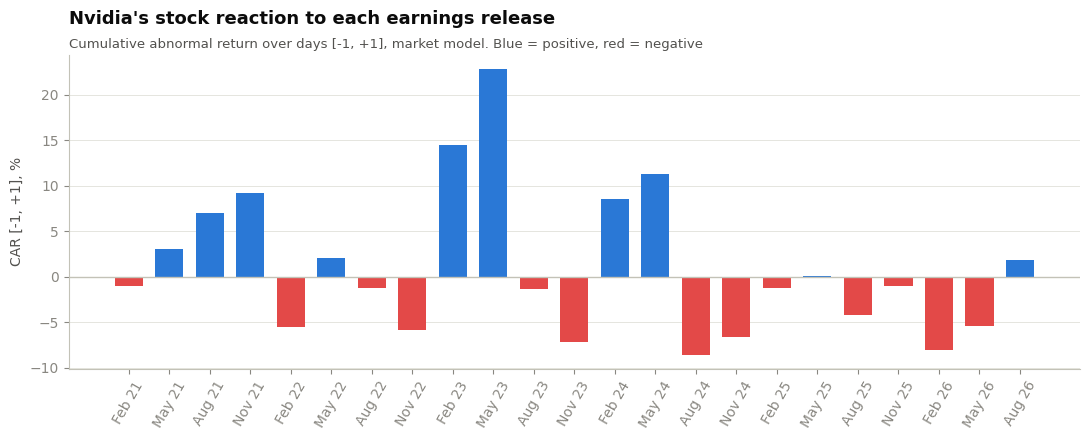

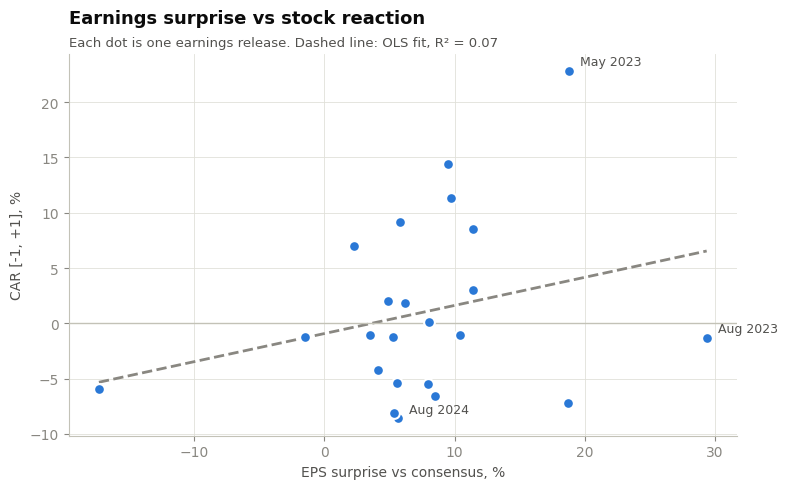

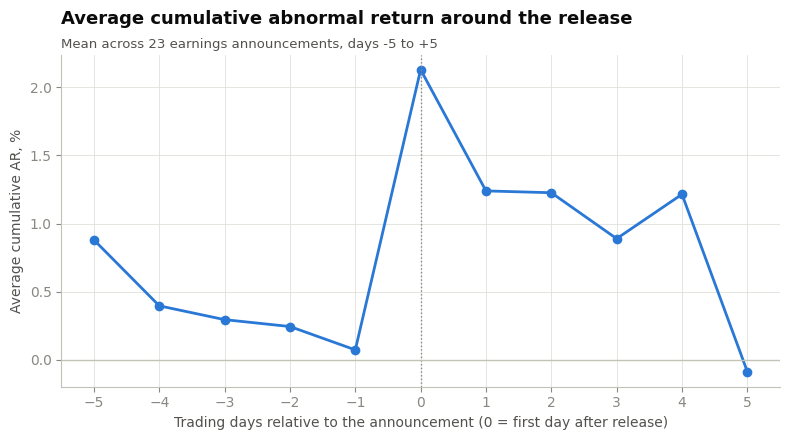

In [14]:
# Stile sobrio, colori chiari
BLU, ROSSO = "#2a78d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "font.size": 10,
    "axes.axisbelow": True,          # griglia dietro le barre
})

def stile(ax, titolo, sottotitolo):
    ax.set_title(titolo, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.02, sottotitolo, transform=ax.transAxes, fontsize=9.5, color="#52514e")

# --- Grafico 1: CAR per trimestrale ---
fig, ax = plt.subplots(figsize=(11, 4.5))
colori = [BLU if c > 0 else ROSSO for c in tab["CAR"]]
etichette = [d.strftime("%b %y") for d in tab.index]
ax.bar(etichette, tab["CAR"] * 100, color=colori, width=0.7)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_ylabel("CAR [-1, +1], %")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
stile(ax, "Nvidia's stock reaction to each earnings release",
      "Cumulative abnormal return over days [-1, +1], market model. Blue = positive, red = negative")
plt.tight_layout()
plt.show()

# --- Grafico 2: CAR vs sorpresa sugli utili ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(tab["Surprise"], tab["CAR"] * 100, s=60, color=BLU,
           edgecolor="white", linewidth=1.5, zorder=3)
xx = np.linspace(tab["Surprise"].min(), tab["Surprise"].max(), 50)
ax.plot(xx, (reg_sorpresa.params["const"] + reg_sorpresa.params["Surprise"] * xx) * 100,
        color=MUTED, linewidth=2, linestyle="--", zorder=2)
for d in [tab["CAR"].idxmax(), tab["CAR"].idxmin(), tab["Surprise"].idxmax()]:
    ax.annotate(d.strftime("%b %Y"), (tab.loc[d, "Surprise"], tab.loc[d, "CAR"] * 100),
                textcoords="offset points", xytext=(8, 4), fontsize=9, color="#52514e")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("EPS surprise vs consensus, %")
ax.set_ylabel("CAR [-1, +1], %")
stile(ax, "Earnings surprise vs stock reaction",
      f"Each dot is one earnings release. Dashed line: OLS fit, R² = {reg_sorpresa.rsquared:.2f}")
plt.tight_layout()
plt.show()

# --- Grafico 3: CAR medio cumulato giorno per giorno ---
caar = ar_grafico.mean(axis=1).cumsum() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(caar.index, caar.values, color=BLU, linewidth=2, marker="o", markersize=6)
ax.axvline(0, color=MUTED, linewidth=1, linestyle=":")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks(list(caar.index))
ax.set_xlabel("Trading days relative to the announcement (0 = first day after release)")
ax.set_ylabel("Average cumulative AR, %")
stile(ax, "Average cumulative abnormal return around the release",
      f"Mean across {ar_grafico.shape[1]} earnings announcements, days {FINESTRA_GRAFICO[0]} to +{FINESTRA_GRAFICO[1]}")
plt.tight_layout()
plt.show()

## 8. Findings, limitations and next steps

**Findings** (23 earnings announcements, Feb 2021 – Aug 2026)

1. **No systematic direction.** The mean CAR[-1,+1] is +0.99%, but the median is −1.04% and only 43% of announcements have a positive CAR. Neither the t-test (p = 0.56) nor the Wilcoxon test (p = 0.87) rejects a zero reaction. Excluding the single largest event (May 2023), the mean CAR falls to 0.00%.
2. **But earnings releases are major information events.** The average absolute CAR is 6.0%, and 7 of 23 announcements are individually significant at the 5% level (|SCAR| > 1.96), against about 1 expected by chance. The stock moves a lot; the direction is what is hard to predict.
3. **The EPS surprise explains little of the reaction.** Nvidia beat the consensus EPS in 21 of 23 quarters, yet the CAR is negative in 13 of 23. In a cross-sectional regression, the surprise coefficient is small and not significant (0.25 pp of CAR per 1 pp of surprise, p = 0.22, robust s.e.), with R² = 0.07. The largest surprise (Aug 2023, +29%) produced a CAR of −1.3%, while a smaller one in May 2023 (+19%) produced the largest CAR of the sample (+22.8%), driven by the revenue guidance.
4. **The average day-0 jump does not persist.** The average abnormal return on the first trading day after the release is about +2%, but the cumulative average is back to roughly zero by day +5 (descriptive, not formally tested).

**Interpretation.** About 93% of the variation in Nvidia's earnings-day reactions is not explained by the EPS surprise. This is consistent with prices reacting to guidance, to commentary on AI demand and to expectations above the published consensus (the "whisper number") rather than to the reported EPS. The correlation between surprise and CAR is 0.45 before May 2023 (9 events) and 0.31 since (14 events): a weaker link in the AI era, though the subsamples are too small for a formal comparison. Testing the narrative channel directly requires guidance and forward-estimate data (see next steps).

**Limitations**
- Small sample (23 events); single quarters weigh heavily, as the May 2023 result shows.
- Consensus EPS comes from Yahoo Finance, not from I/B/E/S.
- Aug 2022: Nvidia pre-announced weak results on 8 Aug 2022, so the official release carried little new information.
- Daily returns have fat tails (residual kurtosis ≈ 11); the Wilcoxon test is reported alongside the t-test for this reason.
- Joint-hypothesis problem: abnormal returns are only as good as the market model behind them. Nvidia's beta also changed strongly over the period (1.3 to 2.9), which is why it is re-estimated before each event.

**Next steps**
- Decompose each price reaction into the change in forward EPS (fundamentals) and the change in forward P/E (narrative), using I/B/E/S consensus data from WRDS.
- Add revenue surprise and guidance surprise as explanatory variables.
- Compare with peers (AMD, Broadcom, TSMC).

*This project is for educational purposes and is not investment advice.*